# The BART model of risk taking

How much risk does a person take, and how strictly do they keep to their
plan? The BART model of Lee & Wagenmakers (2013, chapter 16) answers these
questions from a simple balloon game. This case study takes the PyMC
version of the model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the
   number of pumps. `elicito` learns a prior from each expert. PyMC then
   fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.015.
- The translated model draws 10 000 samples 10 to 20 times faster than
  PyMC.
- The elicited quantiles agree with the quantiles of both experts.
- An expert who agrees with the data changes the posterior only a little.
  An expert who expects too much risk holds the posterior at the bound of
  the Uniform prior.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import pytensor.tensor as pt
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 16], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The balloon task

In the Balloon Analogue Risk Task (BART), a participant pumps up a balloon
on a computer screen. Each pump adds money to a temporary account. The
participant can stop at any time and keep the money. If the balloon
bursts first, the money of this trial is lost.

Each pump bursts the balloon with probability $p = 0.15$. The data are 90
trials of one participant, George, when he is sober.

The figure shows the number of pumps in each trial. A trial ends when
George stops, or when the balloon bursts.

In [4]:
BURST = 0.15  # probability that one pump bursts the balloon

pumps_obs, cash = np.loadtxt("data/GeorgeSober.txt", skiprows=1, usecols=(5, 6)).T
pumps_obs = pumps_obs.astype(int)
stopped = cash != 0  # a burst trial gives no cash

# one row per decision: d is 1 if George stops, k is the number of the pump
d_list: list[int] = []
k_list: list[int] = []
for n_pumps, stop in zip(pumps_obs, stopped.astype(int)):
    d_list += [0] * n_pumps + [1] * stop
    k_list += list(range(1, n_pumps + stop + 1))
d, k = np.array(d_list), np.array(k_list)

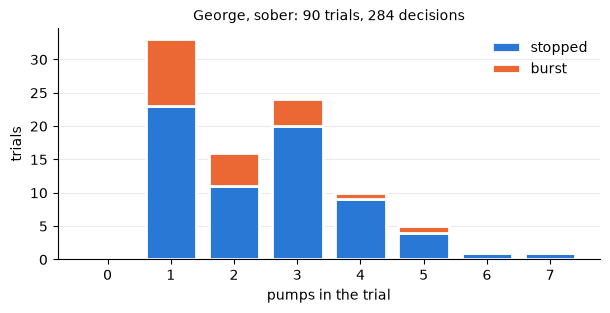

In [5]:
values = np.arange(pumps_obs.max() + 1)
n_stop = np.bincount(pumps_obs[stopped], minlength=values.size)
n_burst = np.bincount(pumps_obs[~stopped], minlength=values.size)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(values, n_stop, color=BLUE, edgecolor="white", linewidth=2, label="stopped")
ax.bar(
    values,
    n_burst,
    bottom=n_stop,
    color=ORANGE,
    edgecolor="white",
    linewidth=2,
    label="burst",
)
ax.set(
    xlabel="pumps in the trial",
    ylabel="trials",
    xticks=values,
    title=f"George, sober: {len(pumps_obs)} trials, {len(d)} decisions",
)
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

George makes 2.4 pumps per trial on average, and never more than 7. The
balloon bursts in 21 of the 90 trials.

## The model

The model has two parameters:

- $\gamma^+$ (`gammap`), the **risk propensity**. A large value means that
  George takes much risk.
- $\beta$ (`beta`), the **behavioural consistency**. A large value means
  that George keeps strictly to his plan.

George believes that the best number of pumps is

$$\omega = -\frac{\gamma^+}{\log(1 - p)}.$$

At pump number $k$, George stops with the probability

$$\theta_k = \operatorname{logit}^{-1}\bigl(\beta (k - \omega)\bigr).$$

Before pump $\omega$ he probably pumps again. After pump $\omega$ he
probably stops. The decision $d_k$ is 1 if he stops:

$$d_k \sim \operatorname{Bernoulli}(\theta_k), \qquad
\gamma^+ \sim \operatorname{Uniform}(0, 10), \qquad
\beta \sim \operatorname{Uniform}(0, 10).$$

The book model predicts only the decisions $d_k$ of the observed trials.
An expert cannot easily state knowledge about single decisions. We
therefore add an output that an expert can observe: **the number of
pumps in one trial**. A trial with $m$ pumps ends with a stop after pump
$m$, or with a burst at pump $m$:

$$P(m) = A_{m+1}\,\theta_{m+1} + A_m (1 - \theta_m)\,p, \qquad
A_n = \prod_{i < n} (1 - \theta_i)(1 - p).$$

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node.

!!! warning
    The translated model computes in float32. There, $\theta_k$ can be
    exactly 1, and $\log(1 - \theta_k)$ is then $-\infty$. The model
    therefore clips $1 - \theta_k$ before the logarithm. See
    [Supported PyMC functions][supported-pymc-functions].

In [6]:
K = 20  # the largest number of pumps of the output
n = np.arange(1, K + 2)  # pump number n comes after n - 1 pumps
BEFORE = np.tril(np.ones((K + 1, K + 1)), -1)  # BEFORE[n, i] = 1 if i < n
SHIFT = np.eye(K + 1, k=-1)  # moves entry m - 1 to entry m


def uniform_prior(name: str) -> Any:
    """Add a Uniform(0, 10) prior with pm.Data bounds to the model"""
    lower = pm.Data(f"{name}_lower", 0.0)
    upper = pm.Data(f"{name}_upper", 10.0)
    return pm.Uniform(name, lower=lower, upper=upper)


with pm.Model() as model:
    gammap = uniform_prior("gammap")
    beta = uniform_prior("beta")
    omega = pm.Deterministic("omega", -gammap / np.log(1 - BURST))

    # the decisions of the observed trials
    theta_k = pm.math.invlogit(beta * (k - omega))
    pm.Bernoulli("djk", p=theta_k, observed=d)

    # the number of pumps in one trial
    theta_n = pm.math.invlogit(beta * (n - omega))
    log_go_on = pt.log(pt.clip(1 - theta_n, 1e-12, 1.0)) + np.log(1 - BURST)
    alive = pt.exp((BEFORE * log_go_on[..., None, :]).sum(axis=-1))  # A_n
    stop = alive * theta_n
    burst = alive * (1 - theta_n) * BURST
    p_pumps = stop + (SHIFT * burst[..., None, :]).sum(axis=-1)
    p_pumps = p_pumps / p_pumps.sum(axis=-1, keepdims=True)
    pm.Deterministic("pumps", pm.Categorical.dist(p=p_pumps))

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `djk`,
`omega` and `pumps`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('gammap', 'Uniform'), ('beta', 'Uniform')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. For `djk`, the table shows the largest $D$ of
the 284 decisions.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


OUTPUTS = ("omega", "pumps", "djk")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<8}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<8}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output     TensorFlow mean, sd     PyMC mean, sd       D
omega             30.82, 17.75      30.46, 17.69   0.015
pumps               5.38, 4.36        5.42, 4.44   0.010
djk                 0.04, 0.20        0.04, 0.20   0.003


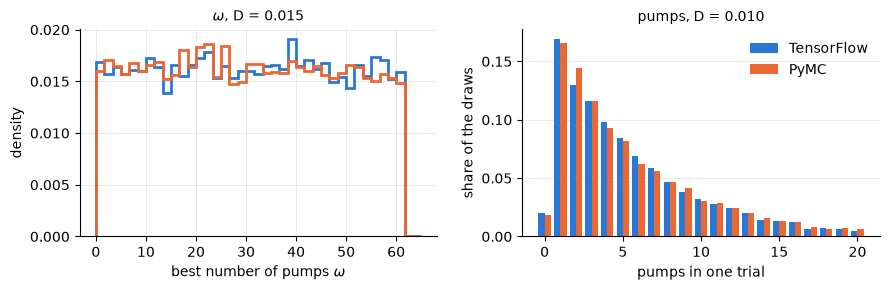

In [9]:
fig, (ax_omega, ax_pumps) = plt.subplots(1, 2, figsize=(9, 3))

bins = np.linspace(0, 65, 40)
for (label, values), color in zip(samples["omega"].items(), (BLUE, ORANGE)):
    ax_omega.hist(
        values[:, 0],
        bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=label,
    )
ax_omega.set(
    xlabel=r"best number of pumps $\omega$",
    ylabel="density",
    title=f"$\\omega$, D = {distance['omega']:.3f}",
)

values_m = np.arange(K + 1)
for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["pumps"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, 0].astype(int), minlength=K + 1) / DRAWS
    ax_pumps.bar(values_m + offset, share, width=0.4, color=color, label=label)
ax_pumps.set(
    xlabel="pumps in one trial",
    ylabel="share of the draws",
    title=f"pumps, D = {distance['pumps']:.3f}",
)
ax_pumps.grid(axis="x", visible=False)
ax_pumps.legend()
fig.tight_layout()
plt.show()

The distributions of the two models overlap. $\omega$ is uniform because
its prior, $\gamma^+ \sim \operatorname{Uniform}(0, 10)$, is uniform.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

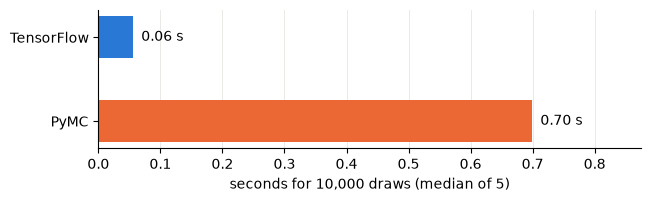

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is 10 to 20 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $\gamma^+$ | $\beta$ | Description |
| :-- | :-- | :-- | :-- |
| A | Uniform(0.3, 0.8) | Uniform(0.5, 1.5) | agrees with the data |
| B | Uniform(1, 2) | Uniform(0.5, 1.5) | expects more risk |

Each expert gives quantiles of two quantities:

- the number of pumps in one trial,
- the best number of pumps $\omega$.

The number of pumps alone is not sufficient. With the pumps alone,
`elicito` can learn a prior with negative $\gamma^+$ and $\beta$. This
prior also gives the quantiles of the expert, but a negative risk
propensity has no meaning. $\omega$ is a model quantity, not an
observation. A real expert can still answer the question "How many pumps
does George plan to make?".

In [12]:
EXPERTS = {
    "Expert A": {"gammap": tfd.Uniform(0.3, 0.8), "beta": tfd.Uniform(0.5, 1.5)},
    "Expert B": {"gammap": tfd.Uniform(1.0, 2.0), "beta": tfd.Uniform(0.5, 1.5)},
}

PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("pumps", probs=PROBS),
    el.quantiles("omega", probs=PROBS),
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

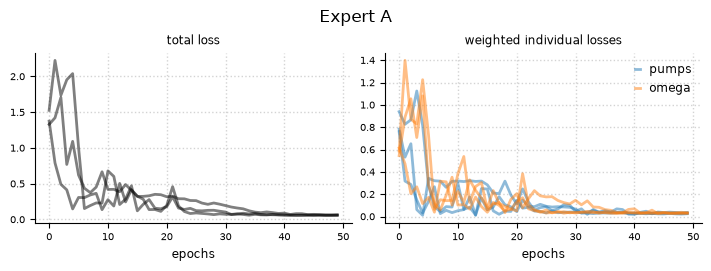

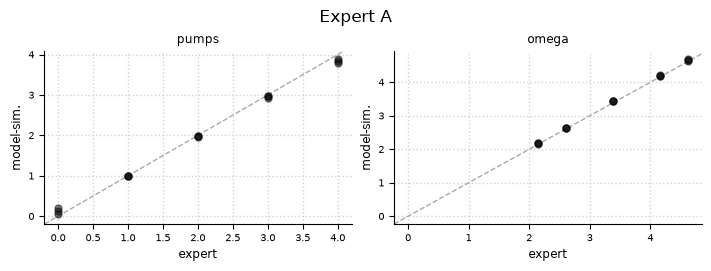

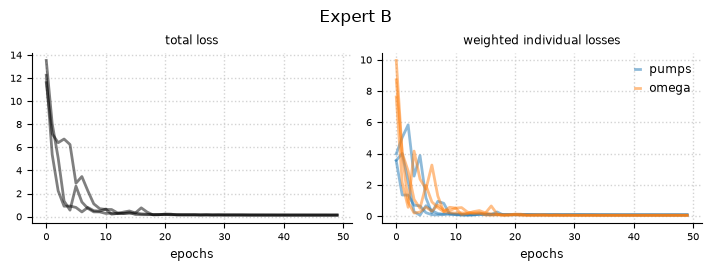

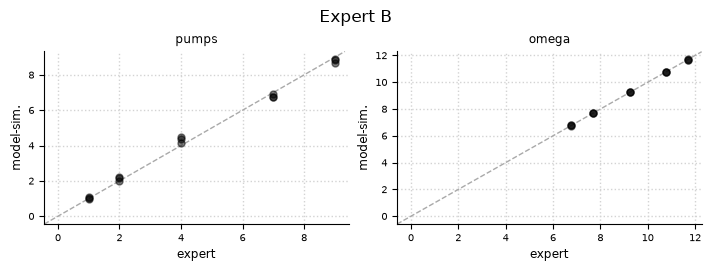

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=2, figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()

A Uniform prior has two bounds. The search can return them in the wrong
order, for example a lower bound of 0.8 and an upper bound of 0.3. The
samples are then the same, but PyMC needs `lower < upper`. We therefore
sort each pair of bounds. We use the replication with the lowest loss.

In [15]:
PARAMETERS = ("gammap", "beta")


def bounds(fit: Any) -> dict[str, tuple[float, float]]:
    """Return the sorted Uniform bounds of each parameter, best replication"""
    values = fit.hyperparameters()
    return {
        name: tuple(sorted((values[f"{name}_lower"], values[f"{name}_upper"])))
        for name in PARAMETERS
    }


PRIORS = {"Book": {name: (0.0, 10.0) for name in PARAMETERS}}
PRIORS |= {expert: bounds(fit) for expert, fit in fits.items()}

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to George's data. The book prior,
Uniform(0, 10), is the reference.

In [16]:
posteriors = {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(
            {
                f"{name}_{side}": value
                for name, pair in prior.items()
                for side, value in zip(("lower", "upper"), pair)
            }
        )
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
    posteriors[label] = idata.posterior

print(f"{'prior':<10}{'parameter':<10}{'mean':>6}{'90 % interval':>16}")
for label, posterior in posteriors.items():
    for name in PARAMETERS:
        values = posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>6.2f}{f'{low:.2f}, {high:.2f}':>16}"
        )

Output()

Output()

Output()

prior     parameter   mean   90 % interval
Book      gammap      0.70      0.63, 0.79
Book      beta        0.74      0.56, 0.94
Expert A  gammap      0.67      0.62, 0.74
Expert A  beta        0.82      0.71, 0.97
Expert B  gammap      1.03      0.99, 1.14
Expert B  beta        0.36      0.28, 0.44


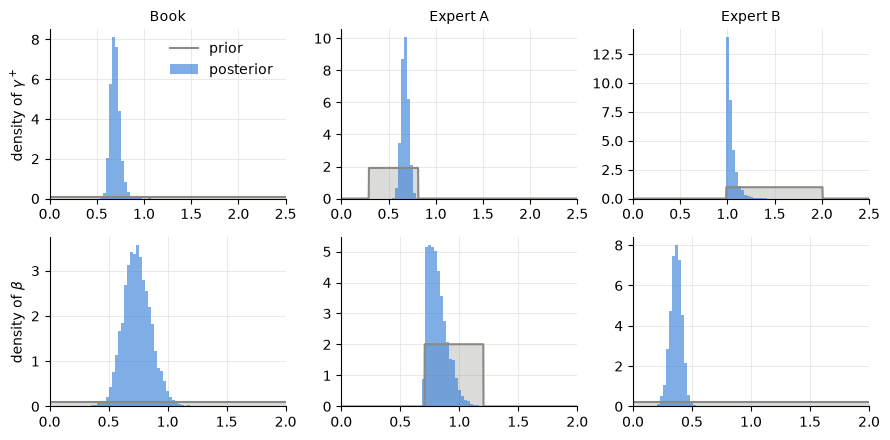

In [17]:
X_RANGE = {"gammap": (0.0, 2.5), "beta": (0.0, 2.0)}
SYMBOL = {"gammap": r"$\gamma^+$", "beta": r"$\beta$"}

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(9, 4.5), sharex="row")
for row, name in enumerate(PARAMETERS):
    grid = np.linspace(*X_RANGE[name], 1000)
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        lower, upper = prior[name]
        prior_density = stats.uniform(lower, upper - lower).pdf(grid)
        ax.fill_between(grid, prior_density, color=GREY, alpha=0.3, lw=0)
        ax.plot(grid, prior_density, color=GREY, lw=1.5, label="prior")
        ax.hist(
            posteriors[label][name].values.ravel(),
            bins=np.linspace(*X_RANGE[name], 80),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        ax.set(xlim=X_RANGE[name])
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of {SYMBOL[name]}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

- **Book prior and expert A.** The posteriors of $\gamma^+$ are almost
  the same (mean 0.70 and 0.67). The data have 284 decisions, so they
  dominate a prior that agrees with them. The prior of $\beta$ from expert
  A is zero below 0.71. The posterior is therefore zero there too.
- **Expert B.** The posterior of $\gamma^+$ stays at the lower bound 1
  (90 % interval 0.99 to 1.14). The data cannot move it past the bound.
  The posterior of $\beta$ moves down to 0.36 instead: the model now
  explains George's few pumps with less consistent behaviour.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the three outputs is 0.015.
- **Speed.** The translated model is 10 to 20 times faster than PyMC.
- **Elicitation.** Check the elicited quantiles against the quantiles of
  the expert. Different priors can give the same quantiles.
- **Uniform priors.** A Uniform prior is a strong statement. The data
  cannot move the posterior past its bounds. A wrong expert then gives a
  wrong posterior.

## Appendix

The PyMC3 model comes from the notebook
[TheBARTModelofRiskTaking.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/TheBARTModelofRiskTaking.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [18]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.